# RAG Assignment: Baseline vs. Re-Ranking

This notebook runs two retrieval pipelines over the **same chunks and the same embedding index** of one PDF (IIIT-H CND curriculum handbook) and sends 3 passages to the **same local LLM** with the **same prompt and decoding settings**.

| | Retrieval | Passages sent to the LLM |
|---|---|---|
| **Pipeline 1 (baseline)** | bi-encoder, cosine similarity, Top-10 | first 3 of the Top-10 |
| **Pipeline 2 (re-ranking)** | the same Top-10, re-scored by a cross-encoder | 3 best by cross-encoder score |

## 0. Setup

In [1]:
%pip install -q pymupdf sentence-transformers transformers accelerate langchain-text-splitters pandas

In [2]:
# ----------------------------- CONFIG -----------------------------
PDF_PATH   = "/content/1.1-CND-Curriculum-Annexure5.pdf"          # the uploaded handbook
EMB_NAME   = "sentence-transformers/all-MiniLM-L6-v2"          # bi-encoder (retriever)
CE_NAME    = "cross-encoder/ms-marco-MiniLM-L-6-v2"            # cross-encoder (re-ranker)
LLM_NAME   = "Qwen/Qwen2.5-3B-Instruct"                        # generator

USE_4BIT = False

CHUNK_TOKENS  = 200      # chunk size in EMBEDDER tokens (MiniLM silently truncates beyond 256)
CHUNK_OVERLAP = 40       # tokens shared by consecutive chunks
TOP_N         = 10       # candidates returned by the bi-encoder (input of the re-ranker)
TOP_K         = 3        # passages sent to the LLM
MAX_NEW_TOKENS = 250     # generation length limit
N_TIMING_RUNS  = 20      # repetitions per query in the latency benchmark

SEED        = 42
RESULTS_DIR = "results"  # csv / md outputs
CACHE_DIR   = "cache"    # cached embedding matrices

In [3]:
import os, re, sys, time, random, bisect, hashlib, shutil, textwrap, warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import torch
import pymupdf
import matplotlib.pyplot as plt
from IPython.display import display
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, AutoModelForCausalLM
from langchain_text_splitters import RecursiveCharacterTextSplitter

warnings.filterwarnings("ignore")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

# Fixed seeds so that every run gives the same numbers.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Use the GPU when available, otherwise fall back to the CPU (much slower).
if torch.cuda.is_available():
    DEVICE, LLM_DTYPE = "cuda", torch.float16
    GPU_NAME = torch.cuda.get_device_name(0)
    print("GPU:", GPU_NAME)
else:
    DEVICE, LLM_DTYPE = "cpu", torch.float32
    GPU_NAME = "CPU (no CUDA available)"
    print("WARNING: no GPU found. Falling back to CPU; everything will run, but slowly (and timings are CPU timings).")

# Print library versions for reproducibility.
print("python", sys.version.split()[0])
for pkg in ["torch", "transformers", "sentence-transformers", "pymupdf", "langchain-text-splitters", "pandas", "numpy"]:
    print(f"{pkg:26s}{version(pkg)}")

# Make pandas tables readable in the notebook output.
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 200)

GPU: Tesla T4
python 3.13.15
torch                     2.11.0+cu130
transformers              5.20.1
sentence-transformers     5.7.0
pymupdf                   2.0
langchain-text-splitters  1.1.3
pandas                    2.2.3
numpy                     2.1.3


## 1. Load the document
Extracts text page by page with PyMuPDF, removes the "Page N of M" footer and normalises whitespace.

In [4]:
FOOTER_RE = re.compile(r"Page\s+\d+\s+of\s+\d+", re.IGNORECASE)   # e.g. "Page 17 of 118"


def clean_page_text(raw):
    """Remove the footer and normalise whitespace.

    Spaces/tabs are collapsed, single line breaks (PDF line wraps) become spaces, and blank-line
    paragraph breaks are kept as "\n\n" so the splitter can prefer paragraph boundaries.
    """
    text = FOOTER_RE.sub("", raw)
    text = re.sub(r"[ \t\r\f\v]+", " ", text)
    text = re.sub(r" ?\n ?", "\n", text)
    text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)   # single newline -> space
    text = re.sub(r"\n{2,}", "\n\n", text)         # keep paragraph breaks only
    return text.strip()


def load_pdf(path):
    """Return (full_text, page_starts). page_starts[i] is the character offset where page i+1 begins."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"PDF not found at {path}. Upload it to /content (Files panel) and re-run this cell.")
    pages, page_starts, pos = [], [], 0
    for page in pymupdf.open(path):
        text = clean_page_text(page.get_text("text"))
        page_starts.append(pos)
        pages.append(text)
        pos += len(text) + 1                       # +1 for the single space used to join pages
    return " ".join(pages), page_starts


full_text, page_starts = load_pdf(PDF_PATH)
n_pages = len(page_starts)
n_words = len(full_text.split())
print(f"pages: {n_pages}")
print(f"words: {n_words}")
print(f"characters: {len(full_text)}")
print("\nfirst 300 characters:\n", full_text[:300])

pages: 118
words: 30264
characters: 190277

first 300 characters:
 International Institute of Information Technology, Hyderabad School of Multi-disciplinary Computing

Dual Degree Programme - B.Tech in Computer Science and Master of Science in Computational Natural Sciences by Research

Table of Contents

Sl. No Item 1. Vision and Mission Statements of the School o


## 2. Chunking
Splits the text with `RecursiveCharacterTextSplitter`, measuring size in **embedder tokens** (not characters).

In [5]:
# Why this chunking:
#  * the recursive splitter prefers paragraph, then line, then word boundaries, so chunks rarely start mid-word;
#  * an overlap of 40 tokens (20%) repeats the end of one chunk at the start of the next, so a short
#    fact that sits on a boundary still appears whole in at least one chunk.
emb_tokenizer = AutoTokenizer.from_pretrained(EMB_NAME)
emb_tokenizer.model_max_length = 10**9            # we measure long strings here; avoid the length warning

splitter = RecursiveCharacterTextSplitter.from_huggingface_tokenizer(
    emb_tokenizer,
    chunk_size=CHUNK_TOKENS,
    chunk_overlap=CHUNK_OVERLAP,
    add_start_index=True,                          # character offset of each chunk in full_text
)
split_docs = splitter.create_documents([full_text])

chunks = []
last_start = 0
for i, d in enumerate(split_docs):
    start = d.metadata["start_index"]
    if start < 0:
        probe = d.page_content[:60]                      # first 60 characters of the chunk
        start = full_text.find(probe, last_start)        # search forward from the previous chunk
        if start < 0:                                    # still not found -> stay near the previous chunk
            start = last_start
    last_start = start
    page = bisect.bisect_right(page_starts, start)       # 1-based page number
    chunks.append({"id": i, "page": page, "text": d.page_content})

tok_lengths = [len(emb_tokenizer.encode(c["text"], add_special_tokens=False)) for c in chunks]
print(f"number of chunks: {len(chunks)}")
print(f"token length  min/mean/max: {min(tok_lengths)} / {np.mean(tok_lengths):.1f} / {max(tok_lengths)}")
print(f"chunks above MiniLM's 256-token limit: {sum(t > 256 for t in tok_lengths)}")

# Show two consecutive chunks so that the overlap is visible.
mid = len(chunks) // 2
for c in chunks[mid:mid + 2]:
    print(f"\n--- chunk {c['id']} (page {c['page']}, {tok_lengths[c['id']]} tokens)")
    print(textwrap.fill(c["text"], 120))

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

number of chunks: 323
token length  min/mean/max: 3 / 154.7 / 200
chunks above MiniLM's 256-token limit: 0

--- chunk 161 (page 61, 200 tokens)
PO5 Modern tool usage: Demonstrate requisite hands-on skills to work with a variety of software packages, libraries,
programming languages, and software development environment tools useful in engineering large scale systems PO6 The
engineer and society: Make judicious use of resources and understand the impact of technology across the societal,
ethical, environmental, and economicaspects. PO7 Environment and sustainability: Find technological solutions by
considering the environmental impact for sustainable development PO8 Ethics: Practice principles of professional ethics
and make informed decisions after a due impact analysis. PO9Individual and team work:Work efficiently in individual and
team-oriented projects of varying size, cultural milieu, professional accomplishments, and technological backgrounds.
PO10Communication: Effectively commun

## 3. Models
Loads the bi-encoder, the cross-encoder and the LLM, and defines `generate(prompt)` (chat template, greedy decoding).

In [6]:
# Bi-encoder (retriever) and cross-encoder (re-ranker).
embedder = SentenceTransformer(EMB_NAME, device=DEVICE)
cross = CrossEncoder(CE_NAME, device=DEVICE)
print("bi-encoder max_seq_length:", embedder.max_seq_length)

# LLM (generator): fp16 on the GPU
llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm_kwargs = {"device_map": DEVICE}
if USE_4BIT:
    from transformers import BitsAndBytesConfig
    llm_kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
else:
    llm_kwargs["dtype"] = LLM_DTYPE
try:
    llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, **llm_kwargs)
except TypeError:                                   # older transformers versions call the argument torch_dtype
    llm_kwargs["torch_dtype"] = llm_kwargs.pop("dtype")
    llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, **llm_kwargs)
llm.eval()


def generate(prompt):
    """Send one user message to the chat model and return its reply (greedy decoding, deterministic)."""
    messages = [{"role": "user", "content": prompt}]
    inputs = llm_tok.apply_chat_template(messages, add_generation_prompt=True,
                                         return_tensors="pt", return_dict=True).to(llm.device)
    try:
        with torch.no_grad():
            out = llm.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                               temperature=None, top_p=None, top_k=None)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        print("NOTE: GPU ran out of memory. Restart the runtime, keep the 3B model (USE_4BIT=False) or lower MAX_NEW_TOKENS.")
        return "[GPU OUT OF MEMORY]"
    return llm_tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


# Quick test that the LLM works
print(generate("In one sentence, what is retrieval-augmented generation?"))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Retrieval-augmented generation is a method that combines the strengths of pre-trained language models with manually curated data to enhance text generation quality and diversity.


## 4. Index
Embeds every chunk (L2-normalised, so that cosine similarity is a dot product) into a NumPy matrix. The matrix is cached on disk.

In [7]:
def embed_texts(model, texts, batch_size=64):
    """Encode texts into L2-normalised vectors (numpy, shape [len(texts), dim])."""
    return model.encode(texts, batch_size=batch_size, normalize_embeddings=True,
                        convert_to_numpy=True, show_progress_bar=False)


def build_index(model, model_name, texts):
    """Embed all chunk texts once and cache the matrix; the cache is reused only if model and chunks are unchanged."""
    key = hashlib.md5((model_name + "||" + "\x00".join(texts)).encode("utf-8")).hexdigest()
    path = os.path.join(CACHE_DIR, "index_" + model_name.replace("/", "_") + ".npz")
    if os.path.exists(path):
        cached = np.load(path, allow_pickle=False)
        if str(cached["key"]) == key:
            print("loaded cached index from", path)
            return cached["matrix"]
    matrix = embed_texts(model, texts)
    np.savez(path, matrix=matrix, key=np.array(key))
    print("built index and saved to", path)
    return matrix


index = build_index(embedder, EMB_NAME, [c["text"] for c in chunks])
print("index shape:", index.shape, "(one vector per chunk)")

built index and saved to cache/index_sentence-transformers_all-MiniLM-L6-v2.npz
index shape: (323, 384) (one vector per chunk)


## 5. Pipeline 1: baseline retrieval
Embeds the query, takes the dot product with every chunk vector and returns the Top-10 in rank order. The first 3 are the baseline passages.

In [8]:
def embed_query(model, query, prefix=""):
    """Embed one query"""
    return embed_texts(model, [prefix + query])[0]


def vector_search(q_vec, idx, top_n=TOP_N):
    """Cosine similarity = dot product (vectors are normalised). Returns (chunk indices, scores) of the top_n."""
    scores = idx @ q_vec
    top = np.argsort(-scores, kind="stable")[:top_n]
    return top, scores[top]


def retrieve_baseline(query, model=embedder, idx=index, prefix=""):
    """Pipeline 1 retrieval: Top-10 chunks as dicts (rank, id, page, score, text) in rank order."""
    q_vec = embed_query(model, query, prefix)
    top, scores = vector_search(q_vec, idx, TOP_N)
    return [{"rank": r + 1, "id": int(i), "page": chunks[i]["page"],
             "score": float(s), "text": chunks[i]["text"]}
            for r, (i, s) in enumerate(zip(top, scores))]


def short(text, n=110):
    """First n characters of a text on a single line (for tables)."""
    return text[:n].replace("\n", " ")


# Demo on one query: the baseline Top-10 and the Top-3 that would go to the LLM.
demo_query = "What is the minimum CGPA required to graduate?"
demo_top10 = retrieve_baseline(demo_query)
baseline_top3 = demo_top10[:TOP_K]
display(pd.DataFrame([{"rank": r["rank"], "chunk_id": r["id"], "page": r["page"],
                       "bi_score": round(r["score"], 4), "text": short(r["text"])} for r in demo_top10]))

,rank,chunk_id,page,bi_score,text
0,1,27,13,0.7074,In order to graduate with B.Tech Honours in Computer Science and Master of Science in ...
1,2,28,13,0.4631,successfully complete 5 CNS electives in the 4th semester and beyond. • Must successfu...
2,3,13,8,0.4252,The remainder of the courses are electives and Honors projects: 1. Humanities electiv...
3,4,26,12,0.4241,0 - - - - - - - Sub Total 3 1 0 0 12 0 0 0 0 4 0 Total 16 V-II Spring Open Electi...
4,5,47,18,0.3722,6. Assessment methods and weightages in brief 1. Programming Assignments (5 to 6) : 5...
5,6,29,13,0.3643,(OC4.101) in the summer at the end of the 3rd year. This is to be registered in the 7t...
6,7,129,47,0.3510,":0-0-3 Credits :2 ( L= Lecture hours, T=Tutorial hours, P=Practical hours) 1.Prerequ..."
7,8,14,8,0.3360,Honors projects – 4 courses (8 credits). Project courses enable students to gain pract...
8,9,30,14,0.3331,Discrete Structures Name of the Academic Program : B. Tech. in CSE Course code : MA5...
9,10,38,16,0.3229,": 3-1-3. Credits : 5 (L = Lecture Hours, T = Tutorial Hours, P = Practical Hours) 1...."


## 6. Pipeline 2: re-ranking with a cross-encoder
Scores all 10 `(query, chunk)` pairs with the cross-encoder and re-sorts them. Both the original bi-encoder rank and the new cross-encoder rank are kept for each candidate.

In [9]:
def cross_scores(query, rows):
    """Cross-encoder relevance score for each (query, chunk text) pair, in the same order as rows."""
    pairs = [(query, r["text"]) for r in rows]
    return cross.predict(pairs, batch_size=len(pairs), show_progress_bar=False)


def rerank(query, top10):
    """Pipeline 2: re-sort exactly the given Top-10 by cross-encoder score (descending).

    Returns all 10 rows with bi_rank/bi_score (old) and ce_rank/ce_score (new). Take [:TOP_K] for the passages.
    """
    scores = cross_scores(query, top10)
    order = np.argsort(-scores, kind="stable")
    out = []
    for new_rank, j in enumerate(order, start=1):
        row = top10[j]
        out.append({"ce_rank": new_rank, "ce_score": float(scores[j]), "bi_rank": row["rank"],
                    "bi_score": row["score"], "id": row["id"], "page": row["page"], "text": row["text"]})
    return out


def run_pipeline2_retrieval(query):
    """Baseline Top-10 followed by re-ranking (used for timing the whole re-ranking pipeline)."""
    return rerank(query, retrieve_baseline(query))


# Demo on the same query as in part 5.
demo_reranked = rerank(demo_query, demo_top10)
display(pd.DataFrame([{"new_rank": r["ce_rank"], "chunk_id": r["id"], "page": r["page"],
                       "ce_score": round(r["ce_score"], 3), "previous_rank": r["bi_rank"],
                       "text": short(r["text"])} for r in demo_reranked]))

,new_rank,chunk_id,page,ce_score,previous_rank,text
0,1,27,13,8.402,1,In order to graduate with B.Tech Honours in Computer Science and Master of Science in ...
1,2,26,12,-8.933,4,0 - - - - - - - Sub Total 3 1 0 0 12 0 0 0 0 4 0 Total 16 V-II Spring Open Electi...
2,3,38,16,-9.142,10,": 3-1-3. Credits : 5 (L = Lecture Hours, T = Tutorial Hours, P = Practical Hours) 1...."
3,4,28,13,-9.238,2,successfully complete 5 CNS electives in the 4th semester and beyond. • Must successfu...
4,5,13,8,-9.814,3,The remainder of the courses are electives and Honors projects: 1. Humanities electiv...
5,6,30,14,-10.100,9,Discrete Structures Name of the Academic Program : B. Tech. in CSE Course code : MA5...
6,7,29,13,-10.149,6,(OC4.101) in the summer at the end of the 3rd year. This is to be registered in the 7t...
7,8,14,8,-10.318,8,Honors projects – 4 courses (8 credits). Project courses enable students to gain pract...
8,9,129,47,-10.730,7,":0-0-3 Credits :2 ( L= Lecture hours, T=Tutorial hours, P=Practical hours) 1.Prerequ..."
9,10,47,18,-10.996,5,6. Assessment methods and weightages in brief 1. Programming Assignments (5 to 6) : 5...


## 7. Prompt and generation
The prompt template is the same for both the pipelines, only the 3 chunks passed to the LLM differ between Answer 1 and Answer 2.

In [10]:
REFUSAL = "I don't know based on the provided documents."

PROMPT_HEADER = (
    "You are an assistant answering questions about the IIIT Hyderabad Dual Degree "
    "(B.Tech CSE + MS by Research in Computational Natural Sciences) curriculum handbook.\n"
    "Answer using ONLY the passages below.\n"
    "Put the passage id after every claim, like [S1].\n"
    "If the passages do not answer the question, reply exactly: " + REFUSAL + "\n"
    "If passages contradict each other, say so and quote both.\n\n"
    "Passages:\n"
)


def build_prompt(question, passages):
    """Instruction, labelled evidence ([S1] (page X) text), then the question last."""
    body = "\n".join(f"[S{i}] (page {p['page']}) {p['text']}" for i, p in enumerate(passages, start=1))
    return PROMPT_HEADER + body + f"\n\nQuestion: {question}\nAnswer:"


_answer_cache = {}   # greedy decoding is deterministic, so an identical prompt need not be generated twice


def answer(question, passages):
    """Generate an answer from the given passages (same function for both pipelines)."""
    prompt = build_prompt(question, passages)
    if prompt not in _answer_cache:
        _answer_cache[prompt] = generate(prompt)
    return _answer_cache[prompt]


def run_both(query):
    """Run Pipeline 1 and Pipeline 2 on one query and return everything needed for the analysis."""
    top10 = retrieve_baseline(query)                 # bi-encoder Top-10 (Pipeline 1 retrieval)
    reranked = rerank(query, top10)                  # same Top-10, re-ranked (Pipeline 2)
    shown1 = top10[:TOP_K]                           # passages for Answer 1
    shown2 = reranked[:TOP_K]                        # passages for Answer 2
    return {"query": query, "top10": top10, "reranked": reranked,
            "shown1": shown1, "shown2": shown2,
            "shown_ids1": [p["id"] for p in shown1], "shown_ids2": [p["id"] for p in shown2],
            "answer1": answer(query, shown1), "answer2": answer(query, shown2)}


print(build_prompt("<question goes here>", [{"page": "X", "text": "<passage text>"}] * 3))

You are an assistant answering questions about the IIIT Hyderabad Dual Degree (B.Tech CSE + MS by Research in Computational Natural Sciences) curriculum handbook.
Answer using ONLY the passages below.
Put the passage id after every claim, like [S1].
If the passages do not answer the question, reply exactly: I don't know based on the provided documents.
If passages contradict each other, say so and quote both.

Passages:
[S1] (page X) <passage text>
[S2] (page X) <passage text>
[S3] (page X) <passage text>

Question: <question goes here>
Answer:


## 8. Gold chunks
A *gold chunk* is a chunk whose text matches the regex that identifies the answer.

In [11]:
# Candidate queries. "gold" = list of case-insensitive regexes that must appear in the chunk holding the answer
# (a query with several patterns is checked per pattern). "keywords" = optional hints for the automatic answer flags.
QUERIES = [
    {"id": "Q1", "category": "negation/limit", "query": "How many CS electives can a student take in one semester?",
     "gold": [r"not\s+more\s+than\s+1\s+in\s+any\s+semester"], "keywords": ["1", "one"]},
    {"id": "Q2", "category": "negation/limit", "query": "Can I take more than two open electives in one semester?",
     "gold": [r"not\s+more\s+than\s+2\s+in\s+any\s+semester"], "keywords": ["2", "two"]},
    {"id": "Q3", "category": "exception/limit", "query": "How many Humanities credits are allowed per semester?",
     "gold": [r"not\s+more\s+than\s+6\s+credits\s+in\s+any\s+semester"], "keywords": ["6"]},
    {"id": "Q4", "category": "contradiction",
     "query": "How many thesis credits must a student register for per semester in the 9th and 10th semesters?",
     "gold": [r"at\s+least\s+12\s+credits\s+in\s+a\s+semester", r"at\s+most\s+12\s+credits\s+in\s+a\s+semester"],
     "keywords": []},
    {"id": "Q5", "category": "exception", "query": "Which courses are assessed as Pass/Fail rather than graded?",
     "gold": [r"This\s+is\s+a\s+Pass/Fail\s+course"], "keywords": ["Value Education", "Pass/Fail"]},
    {"id": "Q6", "category": "keyword trap", "query": "How many credits do I need to graduate?",
     "gold": [r"177\s+course\s+credits\s+and\s+24\s+Thesis\s+credits"], "keywords": ["177", "24"]},
    {"id": "Q7", "category": "buried chunk",
     "query": "What is the end-semester exam weightage for Operating Systems and Networks?",
     "gold": [r"Two\s+Class\s+Room\s+tests:\s*10\s+marks"], "keywords": ["40"]},
    {"id": "Q8", "category": "buried chunk", "query": "What are the prerequisites for Algorithm Analysis and Design?",
     "gold": [r"Pre-?Requisites\s*:\s*Discrete\s+Mathematics,\s+and\s+Data\s+Structures\s+and\s+Algorithms"],
     "keywords": ["Discrete", "Data Structures"]},
    {"id": "Q9", "category": "buried chunk", "query": "Which textbooks are recommended for Operating Systems?",
     "gold": [r"Operating\s+system\s+concepts,\s+Addison"], "keywords": ["Silberschatz"]},
    {"id": "Q10", "category": "control", "query": "What is the minimum CGPA required to graduate?",
     "gold": [r"minimum\s+CGPA\s+required\s+to\s+graduate\s+is\s+7\.00"], "keywords": ["7.00", "7"]},
    {"id": "Q11", "category": "unanswerable", "query": "What is the tuition fee for the dual degree programme?",
     "gold": [], "keywords": [], "absent_terms": ["fee", "fees", "tuition"],
     "expected": "refusal sentence"},
]

EXTRA_QUERIES = [
    # --- PROMOTED (gold moves from rank 4-10 into the re-ranked Top-3) ---
    {"id": "X3", "category": "exception/limit", "query": "What is the ceiling on humanities credits load in any semester?",
     "gold": [r"not\s+more\s+than\s+6\s+credits\s+in\s+any\s+semester"], "keywords": ["6"]},
    {"id": "W2", "category": "keyword trap", "query": "Which course needs Thermodynamics as a prerequisite?",
     "gold": [r"Knowledge\s*:\s*Thermodynamics"], "keywords": ["Statistical"]},

    # --- HURT (gold leaves the Top-3 after re-ranking) ---
    {"id": "X7", "category": "buried chunk", "query": "Which books should I read for the OS course?",
     "gold": [r"Operating\s+system\s+concepts,\s+Addison"], "keywords": ["Silberschatz"]},

    # --- NOT_IN_TOP10 (retrieval misses; re-ranking cannot fix) ---
    {"id": "W1", "category": "keyword trap", "query": "Which course has Linear Algebra as a prerequisite?",
     "gold": [r"Knowledge\s*:\s*Linear\s+Algebra"], "keywords": ["Instrumental"]},
    {"id": "Z1", "category": "keyword trap", "query": "Which course has the code SC2.315?",
     "gold": [r"SC2\.315"], "keywords": ["SC2.315"]},
    {"id": "Z6", "category": "buried chunk", "query": "Which course has a final exam worth 55%?",
     "gold": [r"Final\s+Exam\s+55%"], "keywords": ["55"]},

    # --- contradictions between the curriculum page and the graduation rules ---
    {"id": "Z12", "category": "contradiction", "query": "How many CS electives must a student complete?",
     "gold": [r"4\s+courses\s+\(16\s+credits\)", r"5\s+CS\s+electives"], "keywords": ["4", "5"]},
    {"id": "Z13", "category": "contradiction", "query": "How many humanities electives are required?",
     "gold": [r"2\s+courses\s+\(8\s+credits\)", r"1\s+Humanities\s+electives"], "keywords": ["1", "2"]},
]

ALL_QUERIES = QUERIES + EXTRA_QUERIES
print(f"{len(QUERIES)} built-in queries + {len(EXTRA_QUERIES)} extra queries")

11 built-in queries + 8 extra queries


In [12]:
def find_gold(q):
    """For each gold pattern of a query, the set of chunk ids whose text matches it."""
    return {i: {c["id"] for c in chunks if re.search(pat, c["text"], re.IGNORECASE)}
            for i, pat in enumerate(q["gold"])}


GOLD = {q["id"]: find_gold(q) for q in ALL_QUERIES}      # GOLD[query id][pattern number] -> set of chunk ids


def gold_union(qid):
    """All gold chunk ids of a query (any pattern)."""
    return set().union(*GOLD[qid].values()) if GOLD[qid] else set()


def gold_label(qid, chunk_id):
    """Marker printed next to a chunk: GOLD, or GOLD:P1,P2 for queries with several patterns."""
    hits = [f"P{i + 1}" for i, ids in GOLD[qid].items() if chunk_id in ids]
    if not hits:
        return ""
    return "GOLD" if len(GOLD[qid]) == 1 else "GOLD:" + ",".join(hits)


# Sanity table: how many chunks does each gold pattern match, and where?
rows = []
for q in ALL_QUERIES:
    if not q["gold"]:
        rows.append({"query": q["id"], "pattern": "(none: no gold chunk expected)", "n_matches": "-", "chunk_ids": "-", "pages": "-"})
    for i, pat in enumerate(q["gold"]):
        ids = sorted(GOLD[q["id"]][i])
        rows.append({"query": q["id"], "pattern": f"P{i + 1}: {pat}", "n_matches": len(ids),
                     "chunk_ids": ids, "pages": sorted({chunks[j]["page"] for j in ids})})
display(pd.DataFrame(rows))

# Loud warning for patterns that match nothing (phrase split across chunks or extracted differently).
for q in ALL_QUERIES:
    for i, pat in enumerate(q["gold"]):
        if not GOLD[q["id"]][i]:
            print("!" * 100)
            print(f"WARNING: pattern P{i + 1} of {q['id']} matches 0 chunks: {pat}")
            print("The phrase may be split across two chunks or extracted differently from the PDF. Fix the pattern "
                  "(search full_text for a shorter phrase) and re-run this cell. This query is marked GOLD_NOT_FOUND below.")
            print("!" * 100)

# For queries expected to be unanswerable: confirm with a plain keyword search that the key words are absent.
for q in ALL_QUERIES:
    if q.get("absent_terms"):
        pattern = r"\b(" + "|".join(q["absent_terms"]) + r")\b"
        found = [m for m in re.finditer(pattern, full_text, re.IGNORECASE)]
        print(f"\n{q['id']}: keyword search for {q['absent_terms']} in the whole document -> {len(found)} occurrence(s)")
        for m in found[:5]:
            print("   ...", full_text[max(0, m.start() - 60): m.end() + 60].replace("\n", " "), "...")

,query,pattern,n_matches,chunk_ids,pages
0,Q1,P1: not\s+more\s+than\s+1\s+in\s+any\s+semester,2,"[27, 28]",[13]
1,Q2,P1: not\s+more\s+than\s+2\s+in\s+any\s+semester,1,[28],[13]
2,Q3,P1: not\s+more\s+than\s+6\s+credits\s+in\s+any\s+semester,1,[28],[13]
3,Q4,P1: at\s+least\s+12\s+credits\s+in\s+a\s+semester,1,[13],[8]
4,Q4,P2: at\s+most\s+12\s+credits\s+in\s+a\s+semester,1,[29],[13]
5,Q5,P1: This\s+is\s+a\s+Pass/Fail\s+course,2,"[74, 198]","[27, 71]"
6,Q6,P1: 177\s+course\s+credits\s+and\s+24\s+Thesis\s+credits,1,[27],[13]
7,Q7,P1: Two\s+Class\s+Room\s+tests:\s*10\s+marks,1,[204],[74]
8,Q8,"P1: Pre-?Requisites\s*:\s*Discrete\s+Mathematics,\s+and\s+Data\s+Structures\s+and\s+Al...",1,[150],[56]
9,Q9,"P1: Operating\s+system\s+concepts,\s+Addison",1,[203],[73]



Q11: keyword search for ['fee', 'fees', 'tuition'] in the whole document -> 0 occurrence(s)


## 9. Candidate query mining (retrieval only, no LLM)
Runs every query through Pipeline 1 and Pipeline 2 retrieval and compares the rank of the best gold chunk.

Flags:

`PROMOTED` = gold moved from baseline rank 4-10 into the re-ranked Top-3

`HURT` = gold left the Top-3

`NOT_IN_TOP10` = the baseline never retrieved it (re-ranking cannot fix that)

`STILL_OUTSIDE_TOP3` = in the Top-10 but outside the Top-3 both times.

Rank shift = baseline rank minus re-ranked rank (positive = moved up).

In [13]:
def fmt_rank(r):
    """Rank for display: the number, or 'not in top-10'."""
    return "not in top-10" if r is None else r


def best_rank(ids, rows, key):
    """Best (smallest) rank among the rows whose chunk id is in ids; None if none of them is present."""
    ranks = [r[key] for r in rows if r["id"] in ids]
    return min(ranks) if ranks else None


def flag_for(base, rer):
    """Classify the movement of the best gold chunk."""
    if base is None:
        return "NOT_IN_TOP10"
    if base > TOP_K and rer <= TOP_K:
        return "PROMOTED"
    if base <= TOP_K and rer > TOP_K:
        return "HURT"
    if base > TOP_K and rer > TOP_K:
        return "STILL_OUTSIDE_TOP3"
    return ""


def summarise(q, top10, reranked):
    """One row of the mining table for one query."""
    qid = q["id"]
    row = {"id": qid, "category": q["category"], "query": q["query"]}
    gold = gold_union(qid)
    if not q["gold"]:
        row.update(base_rank="n/a", rerank_rank="n/a", shift="n/a", gold_top3_base="n/a", gold_top3_rerank="n/a",
                   flag="NO_GOLD", per_pattern="")
        return row
    if not gold:
        row.update(base_rank="n/a", rerank_rank="n/a", shift="n/a", gold_top3_base="n/a", gold_top3_rerank="n/a",
                   flag="GOLD_NOT_FOUND", per_pattern="")
        return row
    base = best_rank(gold, top10, "rank")
    rer = best_rank(gold, reranked, "ce_rank")
    per_pattern = ""
    if len(q["gold"]) > 1:                           # record the best rank of each pattern separately
        parts = []
        for i, ids in GOLD[qid].items():
            parts.append(f"P{i + 1}: {fmt_rank(best_rank(ids, top10, 'rank'))} -> {fmt_rank(best_rank(ids, reranked, 'ce_rank'))}")
        per_pattern = "; ".join(parts)
    row.update(base_rank=fmt_rank(base), rerank_rank=fmt_rank(rer),
               shift="n/a" if base is None else f"{base - rer:+d}",
               gold_top3_base=base is not None and base <= TOP_K,
               gold_top3_rerank=rer is not None and rer <= TOP_K,
               flag=flag_for(base, rer), per_pattern=per_pattern)
    return row


def mine_queries(model, idx, prefix=""):
    """Run retrieval + re-ranking for all queries. Returns (table, {query id: (top10, reranked)})."""
    rows, details = [], {}
    for q in ALL_QUERIES:
        top10 = retrieve_baseline(q["query"], model, idx, prefix)
        reranked = rerank(q["query"], top10)
        details[q["id"]] = (top10, reranked)
        rows.append(summarise(q, top10, reranked))
    return pd.DataFrame(rows), details


mining_df, MINE_DETAILS = mine_queries(embedder, index)
display(mining_df)
print("\nflag counts:\n", mining_df["flag"].value_counts().to_string())

,id,category,query,base_rank,rerank_rank,shift,gold_top3_base,gold_top3_rerank,flag,per_pattern
0,Q1,negation/limit,How many CS electives can a student take in one semester?,1,1,+0,True,True,,
1,Q2,negation/limit,Can I take more than two open electives in one semester?,1,1,+0,True,True,,
2,Q3,exception/limit,How many Humanities credits are allowed per semester?,2,2,+0,True,True,,
3,Q4,contradiction,How many thesis credits must a student register for per semester in the 9th and 10th s...,1,1,+0,True,True,,P1: 1 -> 2; P2: 2 -> 1
4,Q5,exception,Which courses are assessed as Pass/Fail rather than graded?,2,1,+1,True,True,,
5,Q6,keyword trap,How many credits do I need to graduate?,1,1,+0,True,True,,
6,Q7,buried chunk,What is the end-semester exam weightage for Operating Systems and Networks?,not in top-10,not in top-10,n/a,False,False,NOT_IN_TOP10,
7,Q8,buried chunk,What are the prerequisites for Algorithm Analysis and Design?,2,1,+1,True,True,,
8,Q9,buried chunk,Which textbooks are recommended for Operating Systems?,2,1,+1,True,True,,
9,Q10,control,What is the minimum CGPA required to graduate?,1,1,+0,True,True,,



flag counts:
 flag
                12
NOT_IN_TOP10     4
NO_GOLD          1
PROMOTED         1
HURT             1


## 10. Failure analysis


In [14]:
def show_candidates(qid, result):
    """(a) baseline Top-10 table and (b) re-ranked Top-10 table, with GOLD markers."""
    print("(a) BASELINE Top-10 (bi-encoder)")
    print(pd.DataFrame([{"rank": r["rank"], "chunk_id": r["id"], "page": r["page"], "bi_score": round(r["score"], 4),
                         "text": short(r["text"]), "gold": gold_label(qid, r["id"])}
                        for r in result["top10"]]).to_string(index=False))
    print("\n(b) RE-RANKED Top-10 (cross-encoder)")
    print(pd.DataFrame([{"new_rank": r["ce_rank"], "chunk_id": r["id"], "page": r["page"], "ce_score": round(r["ce_score"], 3),
                         "previous_rank": r["bi_rank"], "text": short(r["text"]), "gold": gold_label(qid, r["id"])}
                        for r in result["reranked"]]).to_string(index=False))


def show_movement(qid, result):
    """(c) one line per gold chunk found in the Top-10: where it was and where it is now."""
    print("\n(c) Gold chunk movement")
    moved = [r for r in result["reranked"] if r["id"] in gold_union(qid)]
    if not GOLD[qid]:
        print("   no gold chunk defined for this query")
    elif not moved:
        print("   no gold chunk in the baseline Top-10 (re-ranking cannot recover it)")
    for r in sorted(moved, key=lambda r: r["bi_rank"]):
        print(f"   Chunk {r['id']} moved from Rank #{r['bi_rank']} -> Rank #{r['ce_rank']}")


def show_answers(result):
    """(d) both answers verbatim, each with the three passages the LLM saw."""
    for label, shown, ans in [("ANSWER 1 (baseline Top-3)", result["shown1"], result["answer1"]),
                              ("ANSWER 2 (re-ranked Top-3)", result["shown2"], result["answer2"])]:
        print(f"\n(d) {label}")
        for i, p in enumerate(shown, start=1):
            print(textwrap.fill(f"   [S{i}] chunk {p['id']}, page {p['page']}: {p['text']}", 130, subsequent_indent="       "))
        print("   >>> " + "\n       ".join(ans.splitlines()))


def auto_flags(q, result):
    """(e) automatic hints for one query: gold phrase shown?, expected keywords present?, refusal sentence?"""
    print("\n(e) Automatic hint flags (aids only)")
    for label, shown, ans in [("Answer 1", result["shown1"], result["answer1"]),
                              ("Answer 2", result["shown2"], result["answer2"])]:
        gold_shown = {f"P{i + 1}": any(re.search(pat, p["text"], re.IGNORECASE) for p in shown)
                      for i, pat in enumerate(q["gold"])} or "n/a (no gold)"
        kw = {k: (k.lower() in ans.lower()) for k in q.get("keywords", [])} or "n/a"
        print(f"   {label}: gold phrase in the 3 shown passages: {gold_shown} | expected keywords in answer: {kw} | "
              f"is exactly the refusal sentence: {ans.strip() == REFUSAL}")


FLAGS = dict(zip(mining_df["id"], mining_df["flag"]))
promoted = [q for q in ALL_QUERIES if FLAGS[q["id"]] == "PROMOTED"]
hurt = [q for q in ALL_QUERIES if FLAGS[q["id"]] == "HURT"]
controls = [q for q in ALL_QUERIES if q["category"] in ("control", "unanswerable")]

selected = []
for q in promoted + controls + hurt:                  # keep order, avoid duplicates
    if q not in selected:
        selected.append(q)

selected += [q for q in ALL_QUERIES if q["id"] in {"Z12"} and q not in selected]
print("PROMOTED queries:", [q["id"] for q in promoted])
print("HURT queries:", [q["id"] for q in hurt])
print("selected for deep dive:", [q["id"] for q in selected])
if len(promoted) < 2:
    print("\n>>> The assignment needs at least 2 PROMOTED failure queries, but only "
          f"{len(promoted)} were found. Add more queries to EXTRA_QUERIES (step 8), re-run from step 8 and try again.")

PROMOTED queries: ['W2']
HURT queries: ['X7']
selected for deep dive: ['W2', 'Q10', 'Q11', 'X7', 'Z12']

>>> The assignment needs at least 2 PROMOTED failure queries, but only 1 were found. Add more queries to EXTRA_QUERIES (step 8), re-run from step 8 and try again.


In [15]:
analysis_log = []     # kept for results/answers.md

for q in selected:
    print("\n" + "=" * 140)
    print(f"{q['id']} [{q['category']}] flag={FLAGS[q['id']]}: {q['query']}")
    print("=" * 140)
    result = run_both(q["query"])
    show_candidates(q["id"], result)
    show_movement(q["id"], result)
    show_answers(result)
    auto_flags(q, result)
    analysis_log.append({"id": q["id"], "category": q["category"], "flag": FLAGS[q["id"]], "result": result})

if DEVICE == "cuda":
    torch.cuda.empty_cache()      # free cached GPU memory after the LLM runs


W2 [keyword trap] flag=PROMOTED: Which course needs Thermodynamics as a prerequisite?
(a) BASELINE Top-10 (bi-encoder)
 rank  chunk_id  page  bi_score                                                                                                           text gold
    1       168    64    0.6244 Assignments : 35 marks, Quizzes  : 15 marks, Mid Exam  : 20 marks, End Exam  : 30 marks  Title of the Course       
    2       169    64    0.6162 : SCI 204 L-T-P  : 2(90mins)-1-0 Credits  : 2 (L= Lecture hours, T=Tutorial hours, P=Practical hours)  1.Prere     
    3        63    24    0.5753 thermodynamic properties using molecular dynamics software 3.Mapping of Course Outcomes (COs) with Program Out     
    4       175    65    0.5571 : Harjinder Singh Name of the Academic Program  : B Tech (CND) Course Code  : SCI 205 L-T-P  : 2(90mins)-1-0 C GOLD
    5       250    91    0.4960 : 4 L - T - P : (L - Lecture hours, T-Tutorial hours, P - Practical hours) Semester, Year : Monsoon semester

## 11. Latency profiling
Warm-up first, then `N_TIMING_RUNS` repetitions over every query. GPU timings use `torch.cuda.synchronize()` and `time.perf_counter`. LLM generation time is reported separately and is not part of the retrieval comparison.

GPU/device: Tesla T4 | 19 queries x 20 runs


,component,mean_ms,std_ms,n_samples,group
0,query embedding,7.155,1.202,380,retrieval
1,vector search (dot product + top-10 sort),0.099,0.024,380,retrieval
2,baseline retrieval total,7.227,1.276,380,retrieval
3,cross-encoder scoring (10 pairs),23.845,2.491,380,retrieval
4,re-ranking pipeline total,31.103,3.176,380,retrieval
5,extra latency from re-ranking,23.876,3.125,380,retrieval


,component,mean_ms,std_ms,n_samples,group
0,LLM generation (not part of retrieval),3812.3,2358.5,3,generation


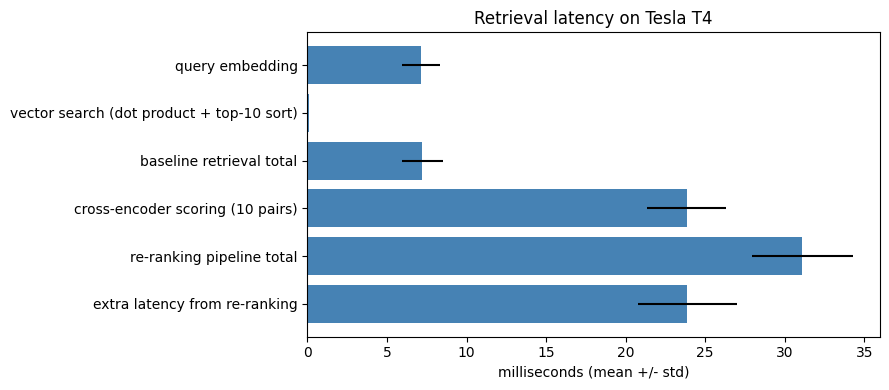

In [16]:
def timed(fn, *args):
    """Run fn(*args) and return (result, elapsed milliseconds); synchronises the GPU before and after."""
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = fn(*args)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    return out, (time.perf_counter() - t0) * 1000


timing_queries = [q["query"] for q in ALL_QUERIES]
print(f"GPU/device: {GPU_NAME} | {len(timing_queries)} queries x {N_TIMING_RUNS} runs")

# Warm-up: the first calls include CUDA initialisation and kernel compilation, so they are not measured.
for _ in range(3):
    run_pipeline2_retrieval(timing_queries[0])

samples = {k: [] for k in ["query embedding", "vector search (dot product + top-10 sort)", "baseline retrieval total",
                           "cross-encoder scoring (10 pairs)", "re-ranking pipeline total", "extra latency from re-ranking"]}
for query in timing_queries:
    for _ in range(N_TIMING_RUNS):
        q_vec, t_embed = timed(embed_query, embedder, query)
        _, t_search = timed(vector_search, q_vec, index, TOP_N)
        top10, t_base = timed(retrieve_baseline, query)                # embedding + search + building rows
        _, t_ce = timed(cross_scores, query, top10)                    # cross-encoder alone
        _, t_pipe = timed(run_pipeline2_retrieval, query)              # baseline retrieval + re-ranking
        for k, v in zip(samples, [t_embed, t_search, t_base, t_ce, t_pipe, t_pipe - t_base]):
            samples[k].append(v)

latency_df = pd.DataFrame([{"component": k, "mean_ms": np.mean(v), "std_ms": np.std(v), "n_samples": len(v)}
                           for k, v in samples.items()]).round(3)
latency_df["group"] = "retrieval"
display(latency_df)

# LLM generation time (reported separately; one baseline prompt for each of the first 3 queries).
llm_ms = []
for q in ALL_QUERIES[:3]:
    prompt = build_prompt(q["query"], retrieve_baseline(q["query"])[:TOP_K])
    _, ms = timed(generate, prompt)
    llm_ms.append(ms)
llm_latency_df = pd.DataFrame([{"component": "LLM generation (not part of retrieval)", "mean_ms": round(np.mean(llm_ms), 1),
                                "std_ms": round(np.std(llm_ms), 1), "n_samples": len(llm_ms), "group": "generation"}])
display(llm_latency_df)

# Bar chart of the retrieval components (error bars = standard deviation).
plt.figure(figsize=(9, 4))
plt.barh(latency_df["component"], latency_df["mean_ms"], xerr=latency_df["std_ms"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("milliseconds (mean +/- std)")
plt.title(f"Retrieval latency on {GPU_NAME}")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "latency.png"), dpi=150)
plt.show()

## 12. Scaling numbers
Extrapolates the measured cost of the cross-encoder to larger collections and compares it with the measured vector search time. The numbers are printed without interpretation.

In [17]:
n_chunks = len(chunks)
lat = latency_df.set_index("component")["mean_ms"]
ce_ms_per_pair = lat["cross-encoder scoring (10 pairs)"] / TOP_N          # measured on batches of 10 pairs
search_ms = lat["vector search (dot product + top-10 sort)"]

scaling_df = pd.DataFrame([
    {"collection": f"this document ({n_chunks} chunks)", "n_chunks": n_chunks,
     "cross_encode_all_seconds": round(ce_ms_per_pair * n_chunks / 1000, 3), "vector_search_ms_measured": round(search_ms, 3)},
    {"collection": "100k chunks (extrapolated)", "n_chunks": 100_000,
     "cross_encode_all_seconds": round(ce_ms_per_pair * 100_000 / 1000, 1), "vector_search_ms_measured": "-"},
    {"collection": "1M chunks (extrapolated)", "n_chunks": 1_000_000,
     "cross_encode_all_seconds": round(ce_ms_per_pair * 1_000_000 / 1000, 1), "vector_search_ms_measured": "-"},
])
print(f"number of chunks N: {n_chunks}")
print(f"measured cross-encoder cost: {ce_ms_per_pair:.3f} ms per (query, chunk) pair (batches of {TOP_N}, {GPU_NAME})")
print("extrapolation = linear (ms per pair x number of chunks), for ONE query\n")
display(scaling_df)
print("Note: chunk embeddings are computed once, offline, and stored. Cross-encoder scores depend on the query, "
      "so they cannot be precomputed and would have to be recomputed for every new query.")

number of chunks N: 323
measured cross-encoder cost: 2.385 ms per (query, chunk) pair (batches of 10, Tesla T4)
extrapolation = linear (ms per pair x number of chunks), for ONE query



,collection,n_chunks,cross_encode_all_seconds,vector_search_ms_measured
0,this document (323 chunks),323,0.77,0.099
1,100k chunks (extrapolated),100000,238.40,-
2,1M chunks (extrapolated),1000000,2384.50,-


Note: chunk embeddings are computed once, offline, and stored. Cross-encoder scores depend on the query, so they cannot be precomputed and would have to be recomputed for every new query.


## 14. Export
Saves the evidence to `results/` (csv files, `answers.md`, `summary.md`) and prints a block of raw numbers for the report.

In [18]:
def df_to_md(df):
    """Render a DataFrame as a markdown table."""
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, row in df.iterrows():
        lines.append("| " + " | ".join(str(v).replace("|", "/") for v in row) + " |")
    return "\n".join(lines)


# 1) mining table (+ bonus table when it was computed)
mining_df.to_csv(os.path.join(RESULTS_DIR, "mining_table.csv"), index=False)

# 2) rank shifts: every Top-10 candidate of every query, with old and new rank
shift_rows = []
for qid, (top10, reranked) in MINE_DETAILS.items():
    for r in reranked:
        shift_rows.append({"query_id": qid, "chunk_id": r["id"], "page": r["page"], "bi_rank": r["bi_rank"],
                           "ce_rank": r["ce_rank"], "rank_shift": r["bi_rank"] - r["ce_rank"],
                           "bi_score": round(r["bi_score"], 4), "ce_score": round(r["ce_score"], 3),
                           "is_gold": bool(gold_label(qid, r["id"]))})
shift_df = pd.DataFrame(shift_rows)
shift_df.to_csv(os.path.join(RESULTS_DIR, "rank_shifts.csv"), index=False)

# 3) latency (retrieval + separate LLM generation row)
all_latency_df = pd.concat([latency_df, llm_latency_df], ignore_index=True)
all_latency_df.to_csv(os.path.join(RESULTS_DIR, "latency.csv"), index=False)

# 4) answers.md: query, passages shown, Answer 1, Answer 2 for every deep-dive query
with open(os.path.join(RESULTS_DIR, "answers.md"), "w", encoding="utf-8") as f:
    for item in analysis_log:
        res = item["result"]
        f.write(f"## {item['id']} ({item['category']}, flag: {item['flag']})\n\n**Query:** {res['query']}\n\n")
        for label, shown, ans in [("Answer 1 (baseline Top-3)", res["shown1"], res["answer1"]),
                                  ("Answer 2 (re-ranked Top-3)", res["shown2"], res["answer2"])]:
            f.write(f"### Passages shown to the LLM for {label}\n\n")
            for i, p in enumerate(shown, start=1):
                f.write(f"- [S{i}] chunk {p['id']}, page {p['page']}: {p['text']}\n")
            f.write(f"\n### {label}\n\n{ans}\n\n")

# 5) summary.md: raw numbers only
with open(os.path.join(RESULTS_DIR, "summary.md"), "w", encoding="utf-8") as f:
    f.write("# Summary of raw results (no interpretation)\n\n")
    f.write(f"- pages: {n_pages}, words: {n_words}, chunks: {len(chunks)}\n")
    f.write(f"- chunk tokens min/mean/max: {min(tok_lengths)}/{np.mean(tok_lengths):.1f}/{max(tok_lengths)}\n")
    f.write(f"- config: chunk={CHUNK_TOKENS} overlap={CHUNK_OVERLAP} top_n={TOP_N} top_k={TOP_K}; "
            f"embedder={EMB_NAME}; cross-encoder={CE_NAME}; llm={LLM_NAME}; device={GPU_NAME}\n\n")
    f.write("## Mining table\n\n" + df_to_md(mining_df) + "\n\n")
    f.write("## Latency (ms)\n\n" + df_to_md(all_latency_df) + "\n\n")
    f.write("## Scaling\n\n" + df_to_md(scaling_df) + "\n")

# 6) facts for the report: raw numbers only
print("=" * 30, "FACTS FOR THE REPORT (raw numbers only)", "=" * 30)
print(f"document: {n_pages} pages, {n_words} words, {len(chunks)} chunks (size {CHUNK_TOKENS} tokens, overlap {CHUNK_OVERLAP})")
print(f"models: {EMB_NAME} | {CE_NAME} | {LLM_NAME} | device: {GPU_NAME}")
print("\nrank of best gold chunk (baseline -> re-ranked):")
for _, r in mining_df.iterrows():
    print(f"  {r['id']:4s} {r['category']:15s} {str(r['base_rank']):>14} -> {str(r['rerank_rank']):<14} flag={r['flag']}  {r['per_pattern']}")
print("\nchunk movements of gold chunks (queries in the deep dive):")
for item in analysis_log:
    for r in sorted(item["result"]["reranked"], key=lambda r: r["bi_rank"]):
        if r["id"] in gold_union(item["id"]):
            print(f"  {item['id']}: chunk {r['id']} moved from Rank #{r['bi_rank']} -> Rank #{r['ce_rank']}")
print("\nlatency (ms, mean +/- std):")
for _, r in all_latency_df.iterrows():
    print(f"  {r['component']:45s} {r['mean_ms']:>9.2f} +/- {r['std_ms']:.2f}")
print("\nscaling: cross-encoder per pair {:.3f} ms; all chunks of this document {:.3f} s; 100k chunks {:.1f} s; 1M chunks {:.1f} s; vector search {:.3f} ms".format(
    ce_ms_per_pair, ce_ms_per_pair * n_chunks / 1000, ce_ms_per_pair * 100_000 / 1000, ce_ms_per_pair * 1_000_000 / 1000, search_ms))
print("\nfiles written to", RESULTS_DIR + "/:", sorted(os.listdir(RESULTS_DIR)))

# Optional: download everything in results/ as a zip when running in Colab.
try:
    from google.colab import files
    shutil.make_archive("results", "zip", RESULTS_DIR)
    files.download("results.zip")
except ImportError:
    print("Not running in Colab: results are in the", RESULTS_DIR, "folder.")

============================== FACTS FOR THE REPORT (raw numbers only) ==============================
document: 118 pages, 30264 words, 323 chunks (size 200 tokens, overlap 40)
models: sentence-transformers/all-MiniLM-L6-v2 | cross-encoder/ms-marco-MiniLM-L-6-v2 | Qwen/Qwen2.5-3B-Instruct | device: Tesla T4

rank of best gold chunk (baseline -> re-ranked):
  Q1   negation/limit               1 -> 1              flag=  
  Q2   negation/limit               1 -> 1              flag=  
  Q3   exception/limit              2 -> 2              flag=  
  Q4   contradiction                1 -> 1              flag=  P1: 1 -> 2; P2: 2 -> 1
  Q5   exception                    2 -> 1              flag=  
  Q6   keyword trap                 1 -> 1              flag=  
  Q7   buried chunk     not in top-10 -> not in top-10  flag=NOT_IN_TOP10  
  Q8   buried chunk                 2 -> 1              flag=  
  Q9   buried chunk                 2 -> 1              flag=  
  Q10  control                 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>